# Train-test split

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/02-data-preparation/train-test-split/train-test-split-notebook.ipynb)

Companion notebook for the *Train-test split* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn function that does the same job.

**Data:** the Breast Cancer Wisconsin data (569 tumors, 30 measurements, malignant or benign).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import model_selection
from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 42
TEST_SHARE = 0.2
REPEATS = 200

X, y = load_breast_cancer(return_X_y=True)
n = len(y)
print(f"{n} tumors, {X.shape[1]} features, malignant share {np.mean(y == 0):.2f}")

569 tumors, 30 features, malignant share 0.37


## 1. Why hold data out

A 1-nearest-neighbor model remembers every training example, so it is always right on them.
Only examples it never saw tell us how good it is.

In [2]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=TEST_SHARE, random_state=RANDOM_STATE)
memorizer = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)
print(f"training accuracy {memorizer.score(X_train, y_train):.3f}")
print(f"test accuracy     {memorizer.score(X_test, y_test):.3f}")

training accuracy 1.000
test accuracy     0.930


## 2. A shuffled split

Shuffle the row numbers, then put the first $n_{\text{test}} = p\,n$ rows in the test set.
With `stratify`, each class $c$ gives $n_{\text{test},c} \approx \pi_c \, n_{\text{test}}$ rows instead (section 3).

In [3]:
def train_test_split(*arrays, test_size=0.25, random_state=None, stratify=None):
    """Shuffle the rows and hold out a share of them as the test set."""
    rng = np.random.default_rng(random_state)
    n = len(arrays[0])
    n_test = int(np.ceil(test_size * n))
    if stratify is None:
        test_rows = rng.permutation(n)[:n_test]
    else:
        test_rows = np.concatenate([rng.permutation(np.flatnonzero(stratify == c))[:round(n_test * np.mean(stratify == c))]
                                    for c in np.unique(stratify)])
    train_rows = np.setdiff1d(np.arange(n), test_rows)
    return [part for array in arrays for part in (array[train_rows], array[test_rows])]


train_rows, test_rows = train_test_split(np.arange(n), test_size=TEST_SHARE, random_state=RANDOM_STATE)
print("train/test sizes:", len(train_rows), len(test_rows), "| overlap:", len(np.intersect1d(train_rows, test_rows)))

train/test sizes: 455 114 | overlap: 0


In [4]:
train_rows_library, test_rows_library = model_selection.train_test_split(np.arange(n), test_size=TEST_SHARE, random_state=RANDOM_STATE)
print("same sizes:", (len(train_rows), len(test_rows)) == (len(train_rows_library), len(test_rows_library)))

same sizes: True


The two functions use different random generators, so they pick different rows; the sizes and the idea are the same.

## 3. A stratified split

Split each class separately so the test set keeps the class shares $\pi_c = n_c / n$.

In [5]:
_, _, _, y_test_by_hand = train_test_split(X, y, test_size=TEST_SHARE, stratify=y, random_state=RANDOM_STATE)
print(f"malignant share: all {np.mean(y == 0):.3f}, stratified test by hand {np.mean(y_test_by_hand == 0):.3f}")

malignant share: all 0.373, stratified test by hand 0.368


In [6]:
_, _, _, y_test_library = model_selection.train_test_split(X, y, test_size=TEST_SHARE, stratify=y, random_state=RANDOM_STATE)
print("same class counts in the test set:", np.array_equal(np.bincount(y_test_by_hand), np.bincount(y_test_library)))

same class counts in the test set: True


## 4. A test score is noisy

With accuracy $a$ on $n_{\text{test}}$ examples the standard error is
$\text{SE} = \sqrt{a(1-a)/n_{\text{test}}}$. Repeat the split many times and compare the spread with the formula.

spread of 200 test scores: 0.021 | formula SE: 0.024


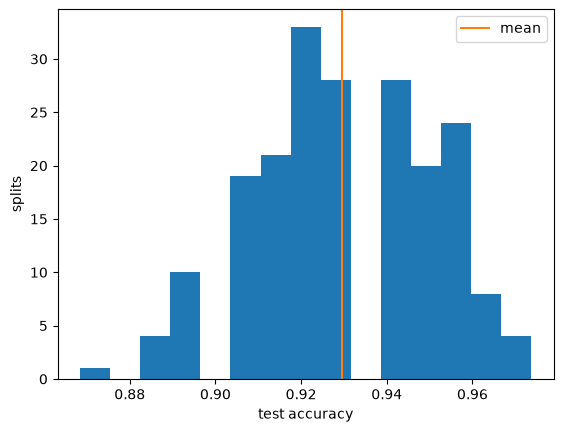

In [7]:
scores = []
for seed in range(REPEATS):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SHARE, random_state=seed)
    model = KNeighborsClassifier().fit(X_train, y_train)
    scores.append(model.score(X_test, y_test))

mean_accuracy = np.mean(scores)
standard_error = np.sqrt(mean_accuracy * (1 - mean_accuracy) / len(y_test))
print(f"spread of {REPEATS} test scores: {np.std(scores):.3f} | formula SE: {standard_error:.3f}")

plt.hist(scores, bins=15)
plt.axvline(mean_accuracy, color="tab:orange", label="mean")
plt.xlabel("test accuracy")
plt.ylabel("splits")
plt.legend()
plt.show()

## Exercises

1. Sort the rows by `y` and split without shuffling. What happens to the class shares?
2. Repeat section 4 with test shares 0.1 and 0.4. How does the spread change?
3. Split into training, validation and test (60/20/20) and use the validation set to choose `n_neighbors`.